In [174]:
# Import Libraries
import requests
import pandas as pd
from bs4 import BeautifulSoup
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [71]:
# for comp in dir(bs4):
#     print(comp)

In [72]:
# Initiate user agent
user_agent={"user-agent":'Mozilla/5.0'}

In [175]:
url="https://en.wikipedia.org/wiki/NMB_Bank_Tanzania" # url 
response=requests.get(url,headers=user_agent) # Requesting
if (response.status_code==200): # Check if requested successfully
    print("Requested Successfully")
else:print(response.status_code)

Requested Successfully


In [ ]:
html=response.text
print(html)

In [ ]:
#  Parse HTML
soup=BeautifulSoup(response.text,'html.parser')
print(soup)

In [76]:
# locate different elements
table=soup.find_all('table',class_="wikitable") #locating table
title=soup.find_all("caption") # locating title of the table

In [77]:
# Extract table title
for comp in title:
    name=comp.get_text(strip=True)
    print(name)
    print()


NMB Bank Plc

NMB Bank Plc shareholding structure as at 30 June 2023



In [176]:
#  Locating tableheader
table_row=soup.find_all('tr')[14:28]

In [140]:
# Extract tr
# for row in table_row:
#     tr=row.get_text(strip=False)
#     for word in tr.split():
#          print(word)
#          print()
#     print()

In [162]:
# Store as dataset
data=[]
dict_data={
    "S/N":[],
    "Shareholder":[],
    "% Ownership":[]
}

# Loop Extraction
for row in table_row:
    tr=row.get_text(strip=False)
    for i,text in enumerate(tr.split(),start=0):
        i_diff=len(tr.split())-(i+1)
        if i_diff==(len(tr.split())-1):
            dict_data["S/N"].append(text)
        elif i_diff==0:
            dict_data["% Ownership"].append(text)
    owners=' '
    for own in tr.split()[1:(len(tr.split())-1)]:
        owners=owners+own+' '
    # print(owners)
    dict_data["Shareholder"].append(owners)
        
# Append Total
dict_data["S/N"].append(" ")
dict_data["Shareholder"].append("Total")
dict_data["% Ownership"].append(np.nan)
ownership_table=pd.DataFrame(dict_data)
display(ownership_table.style.set_properties(**{"background-color":"cyan","color":"black","border":"2px dashed red"}))


,S/N,Shareholder,% Ownership
0,1.,Cooperatieve Centrale Raiffeisen-Boerenleenbank B.A. 'Rabobank Nederland',34.90
1,2.,The Treasury Registrar of Tanzania,31.78
2,3.,NICOL Tanzania,6.61
3,4.,Aunali F Rajabali And Sajjad F Rajabali,5.00
4,5.,SQM Frontier Africa Master Fund Limited,1.91
5,6.,Morgan Stanley Galaxy Fund,1.34
6,7.,Morgan Stanley Institutional Fund Inc.: Frontier Emerging Markets Portfolio,1.24
7,8.,Patrick Schegg,0.99
8,9.,Tanzania Parastatal Pension Fund (PPF),0.97
9,10.,Pinebridge Sub-Saharan Africa Equity Master Fund,0.77


In [154]:
ownership_table.shape

(15, 3)

In [155]:
ownership_table.columns

Index(['S/N', 'Shareholder', '% Ownership'], dtype='str')

In [156]:
ownership_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   S/N          15 non-null     str  
 1   Shareholder  15 non-null     str  
 2   % Ownership  14 non-null     str  
dtypes: str(3)
memory usage: 1.1 KB


In [167]:
#  Alter S/N by removing . and format % ownership dataype
ownership_table["S/N"]=ownership_table["S/N"].str.replace("."," ")
ownership_table["% Ownership"]=pd.to_numeric(ownership_table["% Ownership"],errors="coerce")
ownership_table["% Ownership"]=ownership_table["% Ownership"].fillna(ownership_table["% Ownership"].sum())


In [168]:
#  Print first five rows
ownership_table.head().style.set_properties(**{"background-color":"cyan","color":"black","border":"2px dashed red"})

,S/N,Shareholder,% Ownership
0,1,Cooperatieve Centrale Raiffeisen-Boerenleenbank B.A. 'Rabobank Nederland',34.900000
1,2,The Treasury Registrar of Tanzania,31.780000
2,3,NICOL Tanzania,6.610000
3,4,Aunali F Rajabali And Sajjad F Rajabali,5.000000
4,5,SQM Frontier Africa Master Fund Limited,1.910000


In [166]:
#  Print last five rows

ownership_table.tail().style.set_properties(**{"background-color":"cyan","color":"black","border":"2px dashed red"})

,S/N,Shareholder,% Ownership
10,11,Kuwait Investment Authority,0.700000
11,12,Duet Africa Opportunities Master Fund,0.630000
12,13,TCCIA Investment Company Limited,0.520000
13,14,Other public and private shareholders,12.640000
14,,Total,100.000000


In [158]:
ownership_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   S/N          15 non-null     str    
 1   Shareholder  15 non-null     str    
 2   % Ownership  15 non-null     float64
dtypes: float64(1), str(2)
memory usage: 1.1 KB


In [159]:
df=ownership_table.copy()

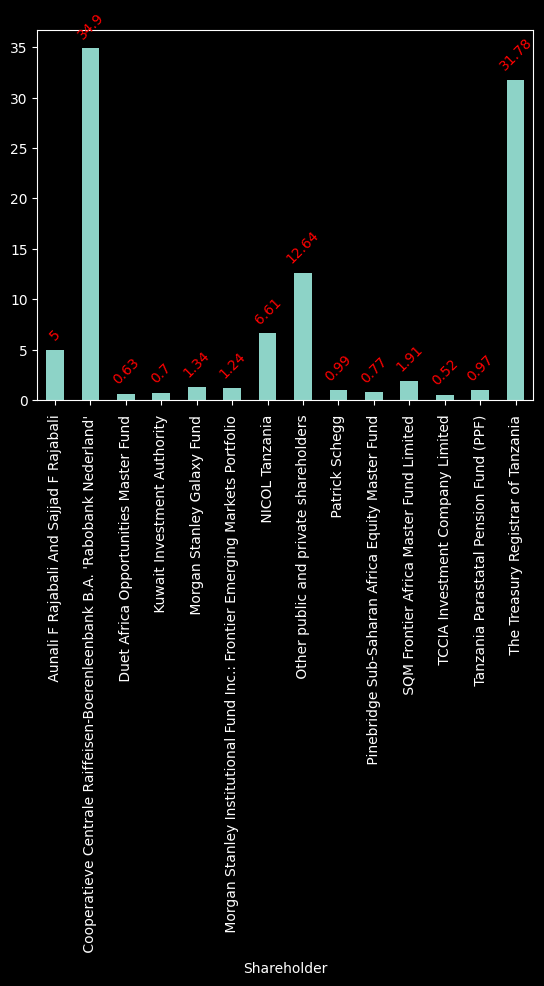

In [185]:
#  Pivot chart
piv_table=df.drop(index=14).groupby(df["Shareholder"])["% Ownership"].sum()
ax=piv_table.plot(
    kind="bar"
)
for label in ax.containers:
    ax.bar_label(label,
                 rotation=45,
                 color="red",
                 padding=5)
plt.show()

In [161]:
# Save scrapped table
df.to_csv("web_scrapping/NMB_ownership_table.csv",index=False)